# 01. Data and definitions

**Project aim:** forecast Great Britain's half-hourly electricity demand one day ahead, with
uncertainty ranges, and compare the result with the forecast published by the National
Energy System Operator (NESO).

**Why this matters:** electricity is hard to store at scale, so supply has to match demand
second by second. Day-ahead demand forecasts feed into how generators and suppliers plan
their positions, and how NESO balances the system. A forecast error costs money, because
someone has to buy or sell the difference closer to real time.

**What this notebook does:**

1. Downloads NESO's historic demand data.
2. Pins down what the columns mean, because "demand" has several definitions.
3. Checks the data before anything is built on it.

Each step says what is being done and why, followed by what the data showed.

**Background reading**
- [Electricity sector in the United Kingdom](https://en.wikipedia.org/wiki/Electricity_sector_in_the_United_Kingdom): an overview of the system.
- [National Grid (Great Britain)](https://en.wikipedia.org/wiki/National_Grid_(Great_Britain)): how the transmission network works.
- [Forecasting: Principles and Practice](https://otexts.com/fpp3/): the textbook I am using for forecasting method.


## Step 1. Set up

**What:** import libraries and fix where files go.

**Why:** paths are relative to this notebook, so it runs on any machine. Raw files are
kept apart from anything derived from them, so a mistake in cleaning can never damage the
original download.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

RAW = Path("../data/raw")
RAW.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 90


## Step 2. Download the data

**What:** use NESO's data portal API to find the yearly CSV files in the
[Historic Demand Data](https://www.neso.energy/data-portal/historic-demand-data) dataset,
then save each one.

**Why the API and not a manual download:** anyone can rerun this and get the same files,
and the notebook picks up new yearly files without edits.

**Why start at 2018:** NESO's published day-ahead forecast, which is the benchmark here,
only goes back to April 2021. Starting in 2018 gives a few years of history before that,
including the COVID period, without modelling a much older system with far less solar.

**Why skip files already on disk:** repeat runs should not hit NESO's servers again. Delete
a file to fetch it fresh, which is worth doing now and then because NESO revises past
values (see below).


In [2]:
API = "https://api.neso.energy/api/3/action/package_show"
FIRST_YEAR = 2018

package = requests.get(API, params={"id": "historic-demand-data"}, timeout=60).json()["result"]

urls = {}
for resource in package["resources"]:
    name = resource["name"]
    if name.startswith("Historic Demand Data") and name[-4:].isdigit():
        year = int(name[-4:])
        if year >= FIRST_YEAR:
            urls[year] = resource["url"]

for year, url in sorted(urls.items()):
    path = RAW / f"demanddata_{year}.csv"
    if not path.exists():
        response = requests.get(url, timeout=120)
        response.raise_for_status()
        path.write_bytes(response.content)
    print(year, f"{path.stat().st_size / 1e6:.1f} MB")

print("Licence:", package["license_title"])


2018 1.4 MB
2019 1.6 MB
2020 1.6 MB
2021 1.6 MB
2022 1.7 MB
2023 1.7 MB
2024 1.8 MB
2025 1.9 MB
2026 1.5 MB
Licence: NESO Open Data Licence


**What came back:** one CSV per year, each between about 1.4 and 1.8 MB, released under the
[NESO Open Data Licence](https://www.neso.energy/data-portal/ngeso-open-licence).

Two points from NESO's dataset description affect the rest of the project:

- The data is published **21 days in arrears**. It cannot supply yesterday's demand to a
  forecast made today, so Day 4 has to settle what a forecaster could really have known.
- Past values can be **revised**, especially solar. So these files are not exactly what
  anyone saw at the time.


## Step 3. What does "demand" mean here?

**What:** settle on definitions before looking at any numbers.

**Why:** NESO publishes several demand series, and they differ by thousands of MW. Comparing a
forecast of one against the outturn of another would look like a large error, or worse, a
small one. All values are in MW, averaged over the half hour.

| Column | Meaning |
|---|---|
| `ND` | **National Demand.** What the transmission system has to supply. Excludes station load, pumped storage pumping and interconnector exports. **This is the target.** |
| `TSD` | **Transmission System Demand.** `ND` plus station load, pumped storage pumping and interconnector exports. |
| `ENGLAND_WALES_DEMAND` | The same idea as `ND`, for England and Wales only. |
| `EMBEDDED_WIND_GENERATION`, `EMBEDDED_SOLAR_GENERATION` | NESO's **estimates** of wind and solar on local distribution networks. |
| `EMBEDDED_*_CAPACITY` | Estimated installed capacity of the above. |
| `PUMP_STORAGE_PUMPING` | Power used to pump water uphill at hydro storage sites. |
| `*_FLOW` | Interconnector flows to other countries. Positive is import, negative is export. |

The point that shapes this project: **embedded generation is invisible to the transmission
system**. A rooftop solar panel feeding a house looks like that house using less power. So
`ND` is not the same as how much electricity people use, and it falls on sunny days. Any
model of `ND` has to account for sunshine and wind, as well as the usual temperature and
calendar effects.

**Further reading**
- [Elexon glossary: National Demand](https://elexon.co.uk/glossary/national-demand)
- [NESO dataset page for 2025](https://www.neso.energy/data-portal/historic-demand-data/historic_demand_data_2025), which has the column notes


## Step 4. Compare the yearly files

**What:** read each file on its own and compare columns and date formats, before combining.

**Why:** `pd.concat` will happily merge files that disagree. It fills missing columns with
NaN and raises no error, so differences have to be found by looking.


In [3]:
frames = {path.stem[-4:]: pd.read_csv(path, low_memory=False)
          for path in sorted(RAW.glob("demanddata_*.csv"))}

latest_columns = set(frames["2026"].columns)
summary = pd.DataFrame({
    year: {
        "rows": len(df),
        "first_date_as_written": df["SETTLEMENT_DATE"].iloc[0],
        "columns_missing_vs_2026": ", ".join(sorted(latest_columns - set(df.columns))) or "none",
    }
    for year, df in frames.items()
}).T
summary


,rows,first_date_as_written,columns_missing_vs_2026
2018,17520,01-JAN-2018,"ELECLINK_FLOW, FORECAST_ACTUAL_INDICATOR, GREE..."
2019,17520,01-JAN-2019,"FORECAST_ACTUAL_INDICATOR, SCOTTISH_TRANSFER"
2020,17568,01-JAN-2020,"FORECAST_ACTUAL_INDICATOR, SCOTTISH_TRANSFER"
2021,17520,01-JAN-2021,"FORECAST_ACTUAL_INDICATOR, SCOTTISH_TRANSFER"
2022,17520,01-JAN-2022,"FORECAST_ACTUAL_INDICATOR, SCOTTISH_TRANSFER"
2023,17520,01-Jan-23,FORECAST_ACTUAL_INDICATOR
2024,17568,01-JAN-2024,FORECAST_ACTUAL_INDICATOR
2025,17520,2025-01-01,FORECAST_ACTUAL_INDICATOR
2026,14014,2026-01-01,none


**Found:** the files do not agree with each other.

- **Date formats change**: `01-JAN-2018`, then `01-Jan-23` in 2023 alone, then `2025-01-01`.
- **Columns get added** as new interconnectors open (for example `VIKING_FLOW`, `GREENLINK_FLOW`).

The columns are not a problem, because a link that did not exist yet has no flow. The dates
are a real trap. Left to guess, pandas could misread a format without any error, so each file
gets an explicit format below, and the code stops if none fits.


## Step 5. Parse dates and combine

**What:** try each known date format per file, requiring every row to parse, then stack the files.

**Why require every row:** a format that fits only some rows means something is wrong, and I
want an error at that point, not missing dates later.


In [4]:
DATE_FORMATS = ("%d-%b-%Y", "%d-%b-%y", "%Y-%m-%d")


def parse_settlement_dates(values):
    """Parse one file's dates, using the single format that fits every row."""
    for date_format in DATE_FORMATS:
        parsed = pd.to_datetime(values, format=date_format, errors="coerce")
        if parsed.notna().all():
            return parsed
    raise ValueError(f"No known date format fits, for example {values.iloc[0]!r}")


parts = []
for year, df in frames.items():
    part = df.copy()
    part["date"] = parse_settlement_dates(part["SETTLEMENT_DATE"])
    parts.append(part)

demand = pd.concat(parts, ignore_index=True).sort_values(["date", "SETTLEMENT_PERIOD"], ignore_index=True)
print(demand.shape)
print(demand["date"].min().date(), "to", demand["date"].max().date())


(154270, 24)
2018-01-01 to 2026-10-19


## Step 6. Basic quality checks

**What:** look for duplicate half-hours, missing values and impossible numbers.

**Why:** these checks are cheap, and a modelling problem caused by bad rows is expensive to
trace later.


In [5]:
print("Duplicate date and period pairs:", demand.duplicated(["date", "SETTLEMENT_PERIOD"]).sum())

missing = demand.isna().mean().round(3)
print("\nShare missing, columns with any gaps:")
print(missing[missing > 0].to_string())

print("\nZero values in England and Wales demand:", (demand["ENGLAND_WALES_DEMAND"] == 0).sum())

columns = ["ND", "TSD", "EMBEDDED_WIND_GENERATION", "EMBEDDED_SOLAR_GENERATION"]
demand[columns].describe().round(0).loc[["min", "50%", "max"]]


Duplicate date and period pairs: 0

Share missing, columns with any gaps:
NSL_FLOW                     0.114
ELECLINK_FLOW                0.114
VIKING_FLOW                  0.114
GREENLINK_FLOW               0.114
SCOTTISH_TRANSFER            0.568
FORECAST_ACTUAL_INDICATOR    0.909

Zero values in England and Wales demand: 3


,ND,TSD,EMBEDDED_WIND_GENERATION,EMBEDDED_SOLAR_GENERATION
min,12626.0,13803.0,125.0,0.0
50%,26410.0,28232.0,1546.0,9.0
max,49807.0,50608.0,5962.0,16393.0


**Found:** no duplicates, and no gaps in the target. The gaps are all in columns that did not
exist in earlier years. Three rows in 2018 have `ENGLAND_WALES_DEMAND` equal to 0, which cannot
be right. That column is not the target, so I will simply not use it.

`ND` runs from 12,626 MW to 49,807 MW, which is a believable range. The lowest value is on a
Sunday lunchtime in May 2026 and the highest is an evening in the March 2018 cold spell known as
the [Beast from the East](https://en.wikipedia.org/wiki/2018_Great_Britain_and_Ireland_cold_wave).


## Step 7. Settlement periods and clock changes

**What:** count the half-hour periods in each day.

**Why:** the GB market divides each day into **settlement periods**, numbered from 1 at
midnight. A normal day has 48. When clocks go forward in March the day is 23 hours, so 46
periods. When they go back in October it has 25 hours, so 50. Code that assumes `period / 2`
gives the hour will be wrong for the rest of those days, and code that assumes 48 rows a day
will misalign everything after them.

**Further reading:** Elexon's notes on the
[46-period](https://elexon.co.uk/article/settlement-short-clock-change-27-march-2022) and
[50-period](https://www.elexon.co.uk/event/volume-notification-on-long-clock-change-day/) days.


In [6]:
periods_per_day = demand.groupby("date").size()
print(periods_per_day.value_counts().to_string())

unusual = periods_per_day[periods_per_day != 48]
pd.DataFrame({"periods": unusual, "weekday": unusual.index.day_name()})


48    3197
46       9
50       8


,periods,weekday
date,,
2018-03-25,46,Sunday
2018-10-28,50,Sunday
2019-03-31,46,Sunday
2019-10-27,50,Sunday
2020-03-29,46,Sunday
2020-10-25,50,Sunday
2021-03-28,46,Sunday
2021-10-31,50,Sunday
2022-03-27,46,Sunday


**Found:** every day has 48 periods except the clock-change days, all of which fall on Sundays
in March (46) and October (50), as they should. The yearly row totals hide this because a 46 and
a 50 cancel out. Day 2 converts all of this into proper timestamps.


## Step 8. Test the definitions against the data

**What:** NESO's description says `TSD` equals `ND` plus station load, pumping and exports. If so,
`TSD - ND - pumping - exports` should leave only station load, which NESO's FAQ gives as about
500 MW in summer time and 600 MW in winter.

**Why:** this tests my reading of the columns, including the sign of the flows. If it fails, I
have misunderstood something, and I would prefer to learn that now.


In [7]:
flow_columns = [column for column in demand.columns if column.endswith("_FLOW")]
exports = -demand[flow_columns].clip(upper=0).sum(axis=1)

demand["station_load_implied"] = demand["TSD"] - demand["ND"] - demand["PUMP_STORAGE_PUMPING"] - exports
matches = demand["station_load_implied"].between(490, 610)

print("Share of half-hours where the remainder is 500 to 600 MW, by year")
print(matches.groupby(demand["date"].dt.year).mean().round(3).to_string())

recent = demand["date"].dt.year == 2026
print("\n2026 by month: share matching, and median remainder (MW)")
print(pd.DataFrame({
    "share_matching": matches[recent].groupby(demand.loc[recent, "date"].dt.month).mean().round(3),
    "median_remainder": demand.loc[recent].groupby(demand.loc[recent, "date"].dt.month)["station_load_implied"].median(),
}).to_string())


Share of half-hours where the remainder is 500 to 600 MW, by year
date
2018    0.902
2019    0.981
2020    0.986
2021    0.991
2022    0.998
2023    1.000
2024    0.999
2025    0.999
2026    0.624

2026 by month: share matching, and median remainder (MW)
      share_matching  median_remainder
date                                  
1              1.000             600.0
2              1.000             600.0
3              1.000             600.0
4              1.000             500.0
5              1.000             500.0
6              0.556             498.0
7              0.131             472.0
8              0.105             474.0
9              0.157             476.0
10             0.129             470.0


**Found:** the definition holds. From 2022 to 2025 the remainder is 500 to 600 MW in at least
99.8% of half-hours, so the columns and the flow signs are understood correctly. Earlier years
are a little noisier.

**One open question.** The match is perfect until May 2026 and then drops sharply from mid-June
2026: the remainder stops being a flat 500 and typically sits a little under it, with a long
tail of much lower values. The data alone does not say why. It may be a change in how NESO
compiles recent data, or provisional values not yet finalised. This matters because the most
recent months are part of the final test period. Day 2 will check `ND` for those months against
the outturn in NESO's benchmark file.


## Step 9. First look at the target

**What:** three plots: a winter week against a summer week, the change over the years, and the
average summer day in 2018 against 2025.

**Why:** the point is to see the main shapes that a model needs to capture, before any modelling.
Full analysis comes on Day 3.


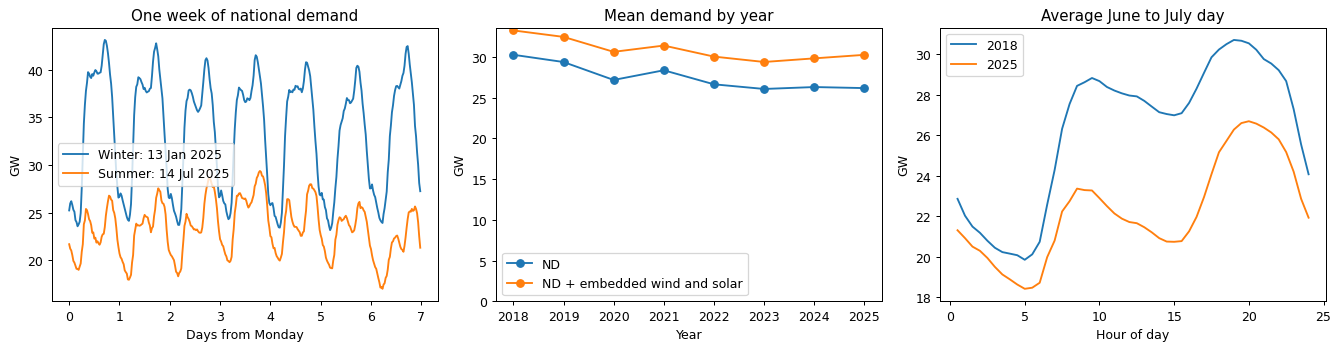

year
2018    13052
2019    13040
2020    13471
2021    14008
2022    15037
2023    16793
2024    18720
2025    22126
2026    23963


In [8]:
def week(start):
    start = pd.Timestamp(start)
    return demand[(demand["date"] >= start) & (demand["date"] < start + pd.Timedelta(days=7))]


fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for start, label in [("2025-01-13", "Winter: 13 Jan 2025"), ("2025-07-14", "Summer: 14 Jul 2025")]:
    axes[0].plot(np.arange(len(week(start))) / 48, week(start)["ND"] / 1000, label=label)
axes[0].set(title="One week of national demand", xlabel="Days from Monday", ylabel="GW")
axes[0].legend()

demand["year"] = demand["date"].dt.year
complete = demand[demand["year"] < 2026]
including_embedded = complete["ND"] + complete["EMBEDDED_WIND_GENERATION"] + complete["EMBEDDED_SOLAR_GENERATION"]
axes[1].plot(sorted(complete["year"].unique()), complete.groupby("year")["ND"].mean() / 1000, "o-", label="ND")
axes[1].plot(sorted(complete["year"].unique()), including_embedded.groupby(complete["year"]).mean() / 1000, "o-",
             label="ND + embedded wind and solar")
axes[1].set(title="Mean demand by year", xlabel="Year", ylabel="GW", ylim=(0, None))
axes[1].legend()

summer = demand[demand["date"].dt.month.isin([6, 7]) & demand["SETTLEMENT_PERIOD"].le(48)]
for year in (2018, 2025):
    profile = summer[summer["year"] == year].groupby("SETTLEMENT_PERIOD")["ND"].mean() / 1000
    axes[2].plot(profile.index / 2, profile.values, label=str(year))
axes[2].set(title="Average June to July day", xlabel="Hour of day", ylabel="GW")
axes[2].legend()

fig.tight_layout()
plt.show()

print(demand.groupby("year")["EMBEDDED_SOLAR_CAPACITY"].last().rename("solar capacity at end of data (MW)").to_string())


**Found:**

- **Daily and weekly rhythm:** clear morning and evening peaks, and lower demand at weekends.
- **Slow decline:** mean `ND` fell from about 30.2 GW in 2018 to 26.2 GW in 2025. Adding embedded
  wind and solar back reduces the fall (33.2 GW to 30.2 GW) but does not remove it. A model
  trained on old years will need some way of handling this drift.
- **Solar reshapes the day:** NESO's estimated embedded solar capacity grew from about 13 GW to
  22 GW between 2018 and 2025. The summer midday demand has dropped noticeably compared with 2018.


## Summary and next step

**What I now know**
- The target is `ND`, and its definition checks out against the data.
- Dates need explicit parsing per file, and clock-change days must be handled by design.
- Sunshine and wind affect the target directly, because embedded generation hides demand.
- Data from mid-June 2026 onwards needs a closer look.

**Next (Day 2):** download NESO's day-ahead forecast, build correct timestamps, confirm that its
outturn matches `ND`, and measure how accurate NESO's forecast is. That sets the bar to beat.

**On method:** the forecast will be evaluated on time-ordered data only, following the approach in
[Forecasting: Principles and Practice, section 5.10](https://otexts.com/fpp3/tscv.html).
